# Phase 1 — Temporal Features

Load the air-quality dataset, build a daily timestamp index, derive calendar features,
and create lag/rolling features for **PM2.5**, **PM10**, and **CO**.

Assumptions (edit the config cell if they change):
- Row order is chronological and each row is one day.
- Row 0 is anchored to `START_DATE`.
- Rolling windows are built on **past days only** (shifted by one day) so the current
  day's PM2.5 target does not leak into its own predictors.

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd

# --- Config ---
DATA_PATH = Path("air_quality_dataset.csv")
OUTPUT_PATH = Path("data/processed/air_quality_features.csv")
START_DATE = "2023-01-01"  # arbitrary anchor: row 0 is this date
FREQ = "D"                 # one reading per day, so lag_1 = previous day

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [13]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Raw shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
raw_df.head()

Raw shape: 500 rows x 10 columns


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


## 0. Clean invalid readings

A few rows contain physically impossible negative concentrations (NOx, NO2, SO2).
They are clipped to 0 so they do not corrupt the lag/rolling features.

In [14]:
df = raw_df.copy()

pollutant_cols = ["PM2.5", "PM10", "NOx", "NO2", "SO2", "VOCs", "CO", "CO2", "CH4"]
negatives = (df[pollutant_cols] < 0).sum()
print("Negative values per pollutant (before cleaning):")
print(negatives[negatives > 0].to_string())

df[pollutant_cols] = df[pollutant_cols].clip(lower=0)
print(f"Remaining negative values: {int((df[pollutant_cols] < 0).sum().sum())}")

Negative values per pollutant (before cleaning):
NOx    1
NO2    1
SO2    2
Remaining negative values: 0


## 1. Build the time index and calendar features

The dataset has no timestamps, so we generate one date per row starting at `START_DATE`.
Seasons use the standard meteorological mapping (Winter Dec–Feb, Spring Mar–May,
Summer Jun–Aug, Autumn Sep–Nov) and can be swapped for a local scheme.

In [15]:
df.insert(0, "timestamp", pd.date_range(start=START_DATE, periods=len(df), freq=FREQ))

df["month"] = df["timestamp"].dt.month
df["day_of_week"] = df["timestamp"].dt.day_name()
df["is_weekend"] = (df["timestamp"].dt.dayofweek >= 5).astype(int)

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
df["season"] = df["month"].map(season_map)

print(f"Time range: {df['timestamp'].min().date()} -> {df['timestamp'].max().date()}")
print(f"Timestamps unique & sorted: {df['timestamp'].is_unique and df['timestamp'].is_monotonic_increasing}")
df[["timestamp", "month", "day_of_week", "season", "is_weekend"]].head()

Time range: 2023-01-01 -> 2024-05-14
Timestamps unique & sorted: True


/var/folders/bw/tmg6lqwx7s9b3p15vl877jlm0000gn/T/ipykernel_2298/1004574919.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["is_weekend"] = (df["timestamp"].dt.dayofweek >= 5).astype(int)


,timestamp,month,day_of_week,season,is_weekend
0,2023-01-01,1,Sunday,Winter,1
1,2023-01-02,1,Monday,Winter,0
2,2023-01-03,1,Tuesday,Winter,0
3,2023-01-04,1,Wednesday,Winter,0
4,2023-01-05,1,Thursday,Winter,0


## 2. Lag and rolling features

- `pm2_5_lag_1`, `pm2_5_lag_3`, `pm2_5_lag_7` — previous day / 3 days ago / 7 days ago PM2.5.
- `pm2_5_mean_3d`, `pm2_5_mean_7d` — mean PM2.5 over the previous 3 / 7 days.
- `pm2_5_std_7d` — volatility of PM2.5 over the previous 7 days.
- `pm10_lag_1`, `co_lag_1` — previous day's PM10 and CO.

Column names sanitize `PM2.5` to `pm2_5` so they are valid Python identifiers.
The first rows will be `NaN` because there is no history yet (warm-up period).

In [16]:
# PM2.5 lags
df["pm2_5_lag_1"] = df["PM2.5"].shift(1)
df["pm2_5_lag_3"] = df["PM2.5"].shift(3)
df["pm2_5_lag_7"] = df["PM2.5"].shift(7)

# PM2.5 rolling stats over previous days (shift avoids target leakage)
pm2_5_history = df["PM2.5"].shift(1)
df["pm2_5_mean_3d"] = pm2_5_history.rolling(window=3, min_periods=3).mean()
df["pm2_5_mean_7d"] = pm2_5_history.rolling(window=7, min_periods=7).mean()
df["pm2_5_std_7d"] = pm2_5_history.rolling(window=7, min_periods=7).std()

# Cross-pollutant lags
df["pm10_lag_1"] = df["PM10"].shift(1)
df["co_lag_1"] = df["CO"].shift(1)

engineered_cols = [
    "pm2_5_lag_1", "pm2_5_lag_3", "pm2_5_lag_7",
    "pm2_5_mean_3d", "pm2_5_mean_7d", "pm2_5_std_7d",
    "pm10_lag_1", "co_lag_1",
]

print(f"Shape after feature engineering: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Engineered columns ({len(engineered_cols)}): {engineered_cols}")
df[engineered_cols].tail(10)

Shape after feature engineering: 500 rows x 23 columns
Engineered columns (8): ['pm2_5_lag_1', 'pm2_5_lag_3', 'pm2_5_lag_7', 'pm2_5_mean_3d', 'pm2_5_mean_7d', 'pm2_5_std_7d', 'pm10_lag_1', 'co_lag_1']


,pm2_5_lag_1,pm2_5_lag_3,pm2_5_lag_7,pm2_5_mean_3d,pm2_5_mean_7d,pm2_5_std_7d,pm10_lag_1,co_lag_1
490,51.982904,57.001521,28.324850,49.017685,42.042467,13.824235,25.283159,2.725627
491,52.408976,38.068629,59.391663,47.486837,45.483057,12.800291,57.589120,4.412654
492,28.286291,51.982904,26.798764,44.226057,41.039432,12.564126,59.113872,1.267362
493,59.233746,52.408976,32.728940,46.643004,45.673001,12.416993,97.725832,1.949973
494,37.901434,28.286291,57.001521,41.807157,46.411929,11.648439,52.441719,1.145472
495,47.205592,59.233746,38.068629,48.113591,45.012510,10.715243,62.540984,1.407990
496,51.380025,37.901434,51.982904,45.495684,46.914138,10.455565,57.573550,1.844483
497,46.816837,47.205592,52.408976,48.467485,46.176129,10.217774,75.372133,1.364096
498,33.909351,51.380025,28.286291,44.035404,43.533325,10.717214,88.097250,2.319453
499,43.721651,46.816837,59.233746,41.482613,45.738377,8.393248,40.847991,1.599748


In [17]:
print("NaNs per engineered feature (warm-up rows; drop before modeling):")
print(df[engineered_cols].isna().sum().to_string())

print("\nCorrelation with PM2.5:")
print(df[engineered_cols + ["PM2.5"]].corr()["PM2.5"].sort_values(ascending=False).round(3).to_string())

NaNs per engineered feature (warm-up rows; drop before modeling):
pm2_5_lag_1      1
pm2_5_lag_3      3
pm2_5_lag_7      7
pm2_5_mean_3d    3
pm2_5_mean_7d    7
pm2_5_std_7d     7
pm10_lag_1       1
co_lag_1         1

Correlation with PM2.5:
PM2.5            1.000
pm2_5_lag_7      0.058
pm2_5_lag_3      0.057
pm2_5_std_7d     0.015
pm2_5_mean_3d   -0.037
pm2_5_lag_1     -0.040
pm2_5_mean_7d   -0.042
co_lag_1        -0.055
pm10_lag_1      -0.069


In [18]:
print("Rows by season:")
print(df["season"].value_counts().to_string())
print("\nRows by day of week:")
print(df["day_of_week"].value_counts().to_string())

df.head()

Rows by season:
season
Spring    167
Winter    150
Summer     92
Autumn     91

Rows by day of week:
day_of_week
Sunday       72
Monday       72
Tuesday      72
Wednesday    71
Thursday     71
Friday       71
Saturday     71


,timestamp,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,month,day_of_week,is_weekend,season,pm2_5_lag_1,pm2_5_lag_3,pm2_5_lag_7,pm2_5_mean_3d,pm2_5_mean_7d,pm2_5_std_7d,pm10_lag_1,co_lag_1
0,2023-01-01,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120,1,Sunday,1,Winter,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-02,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103,1,Monday,0,Winter,39.967142,NaN,NaN,NaN,NaN,NaN,57.926035,2.789606
2,2023-01-03,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698,1,Tuesday,0,Winter,101.935672,NaN,NaN,NaN,NaN,NaN,150.774299,1.966569
3,2023-01-04,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877,1,Wednesday,0,Winter,70.996192,39.967142,NaN,70.966335,NaN,NaN,138.948796,2.626446
4,2023-01-05,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835,1,Thursday,0,Winter,28.464728,101.935672,NaN,67.132197,NaN,NaN,63.643900,1.779360


## 3. Save the feature-engineered dataset

Written to `data/processed/air_quality_features.csv` for the modeling phase.

In [19]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {df.shape[0]} rows x {df.shape[1]} columns -> {OUTPUT_PATH}")

Saved 500 rows x 23 columns -> data/processed/air_quality_features.csv


In [20]:
df1 = pd.read_csv("/Users/ashriths/Library/Mobile Documents/com~apple~CloudDocs/Repositries/End to End Data Science Project /data/processed/air_quality_features.csv")
print(df1.head())

    timestamp       PM2.5        PM10         NOx        NO2        SO2        VOCs        CO         CO2       CH4  Temperature  month day_of_week  is_weekend  season  pm2_5_lag_1  pm2_5_lag_3  \
0  2023-01-01   39.967142   57.926035  116.192213  55.230299   4.531693   75.317261  2.789606  427.674347  1.706105    31.085120      1      Sunday           1  Winter          NaN          NaN   
1  2023-01-02  101.935672  150.774299   76.826826  79.051618  18.744780  145.083987  1.966569  529.739619  2.492663    33.711103      1      Monday           0  Winter    39.967142          NaN   
2  2023-01-03   70.996192  138.948796  158.731020  60.466604  14.892239  145.147338  2.626446  499.889443  2.431165    33.778698      1     Tuesday           0  Winter   101.935672          NaN   
3  2023-01-04   28.464728   63.643900   25.385343  15.333286   7.647429  130.022319  1.779360  388.283712  1.818563    31.565877      1   Wednesday           0  Winter    70.996192    39.967142   
4  2023-01-05  

## 4. Cramér's V association analysis

Cramér's V measures the strength of association between two **categorical** variables
(0 = independent, 1 = perfectly associated) and, unlike Pearson correlation, it also
captures **non-linear** relationships.

All pollutant and lag features are continuous, so each is first discretized into
**5 quantile bins (quintiles)**. Calendar features (`month`, `day_of_week`, `season`,
`is_weekend`) are used as-is. `timestamp` is excluded as an identifier.

This section only *reports* associations — **no features are combined or dropped yet.**

In [21]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid", context="notebook")


def cramers_v(x, y):
    """Cramér's V between two categorical Series."""
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))


analysis_cols = [
    "PM2.5", "PM10", "NOx", "NO2", "SO2", "VOCs", "CO", "CO2", "CH4", "Temperature",
    "month", "day_of_week", "season", "is_weekend",
    "pm2_5_lag_1", "pm2_5_lag_3", "pm2_5_lag_7",
    "pm2_5_mean_3d", "pm2_5_mean_7d", "pm2_5_std_7d",
    "pm10_lag_1", "co_lag_1",
]
analysis_cols = [c for c in analysis_cols if c in df.columns]

categorical_cols = {"month", "day_of_week", "season", "is_weekend"}
N_BINS = 5

binned_df = pd.DataFrame(index=df.index)
for col in analysis_cols:
    s = df[col]
    if col not in categorical_cols and pd.api.types.is_numeric_dtype(s) and s.nunique() > N_BINS:
        binned_df[col] = pd.qcut(s, q=N_BINS, duplicates="drop").astype("string")
    else:
        binned_df[col] = s.astype("string")

print(f"Analysed {len(analysis_cols)} features (continuous columns binned into {N_BINS} quintiles)")
binned_df.head()

Analysed 22 features (continuous columns binned into 5 quintiles)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,month,day_of_week,season,is_weekend,pm2_5_lag_1,pm2_5_lag_3,pm2_5_lag_7,pm2_5_mean_3d,pm2_5_mean_7d,pm2_5_std_7d,pm10_lag_1,co_lag_1
0,"(35.0, 43.218]","(57.538, 70.4]","(109.565, 145.753]","(47.13, 69.512]","(-0.001, 5.498]","(27.555, 77.025]","(2.31, 2.918]","(412.389, 431.557]","(1.387, 1.791]","(29.725, 31.263]",1,Sunday,Winter,1,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,"(78.483, 127.617]","(117.075, 171.594]","(32.14, 77.114]","(69.512, 115.916]","(10.198, 18.807]","(117.172, 147.544]","(1.82, 2.31]","(500.386, 558.924]","(2.148, 2.493]","(33.102, 39.779]",1,Monday,Winter,0,"(34.998, 43.277]",<NA>,<NA>,<NA>,<NA>,<NA>,"(57.583, 70.43]","(2.312, 2.92]"
2,"(55.272, 78.483]","(117.075, 171.594]","(145.753, 225.887]","(47.13, 69.512]","(10.198, 18.807]","(117.172, 147.544]","(2.31, 2.918]","(431.557, 500.386]","(2.148, 2.493]","(33.102, 39.779]",1,Tuesday,Winter,0,"(78.531, 127.617]",<NA>,<NA>,<NA>,<NA>,<NA>,"(117.126, 171.594]","(1.821, 2.312]"
3,"(10.757, 35.0]","(57.538, 70.4]","(-0.001, 32.14]","(-0.001, 15.736]","(5.498, 7.656]","(117.172, 147.544]","(1.459, 1.82]","(366.062, 391.491]","(1.791, 1.989]","(31.263, 33.102]",1,Wednesday,Winter,0,"(55.317, 78.531]","(35.022, 43.282]",<NA>,"(65.621, 94.711]",<NA>,<NA>,"(117.126, 171.594]","(2.312, 2.92]"
4,"(55.272, 78.483]","(88.519, 117.075]","(77.114, 109.565]","(47.13, 69.512]","(10.198, 18.807]","(147.544, 231.926]","(2.918, 4.799]","(431.557, 500.386]","(2.493, 3.352]","(31.263, 33.102]",1,Thursday,Winter,0,"(10.757, 34.998]","(78.628, 127.617]",<NA>,"(65.621, 94.711]",<NA>,<NA>,"(57.583, 70.43]","(1.458, 1.821]"


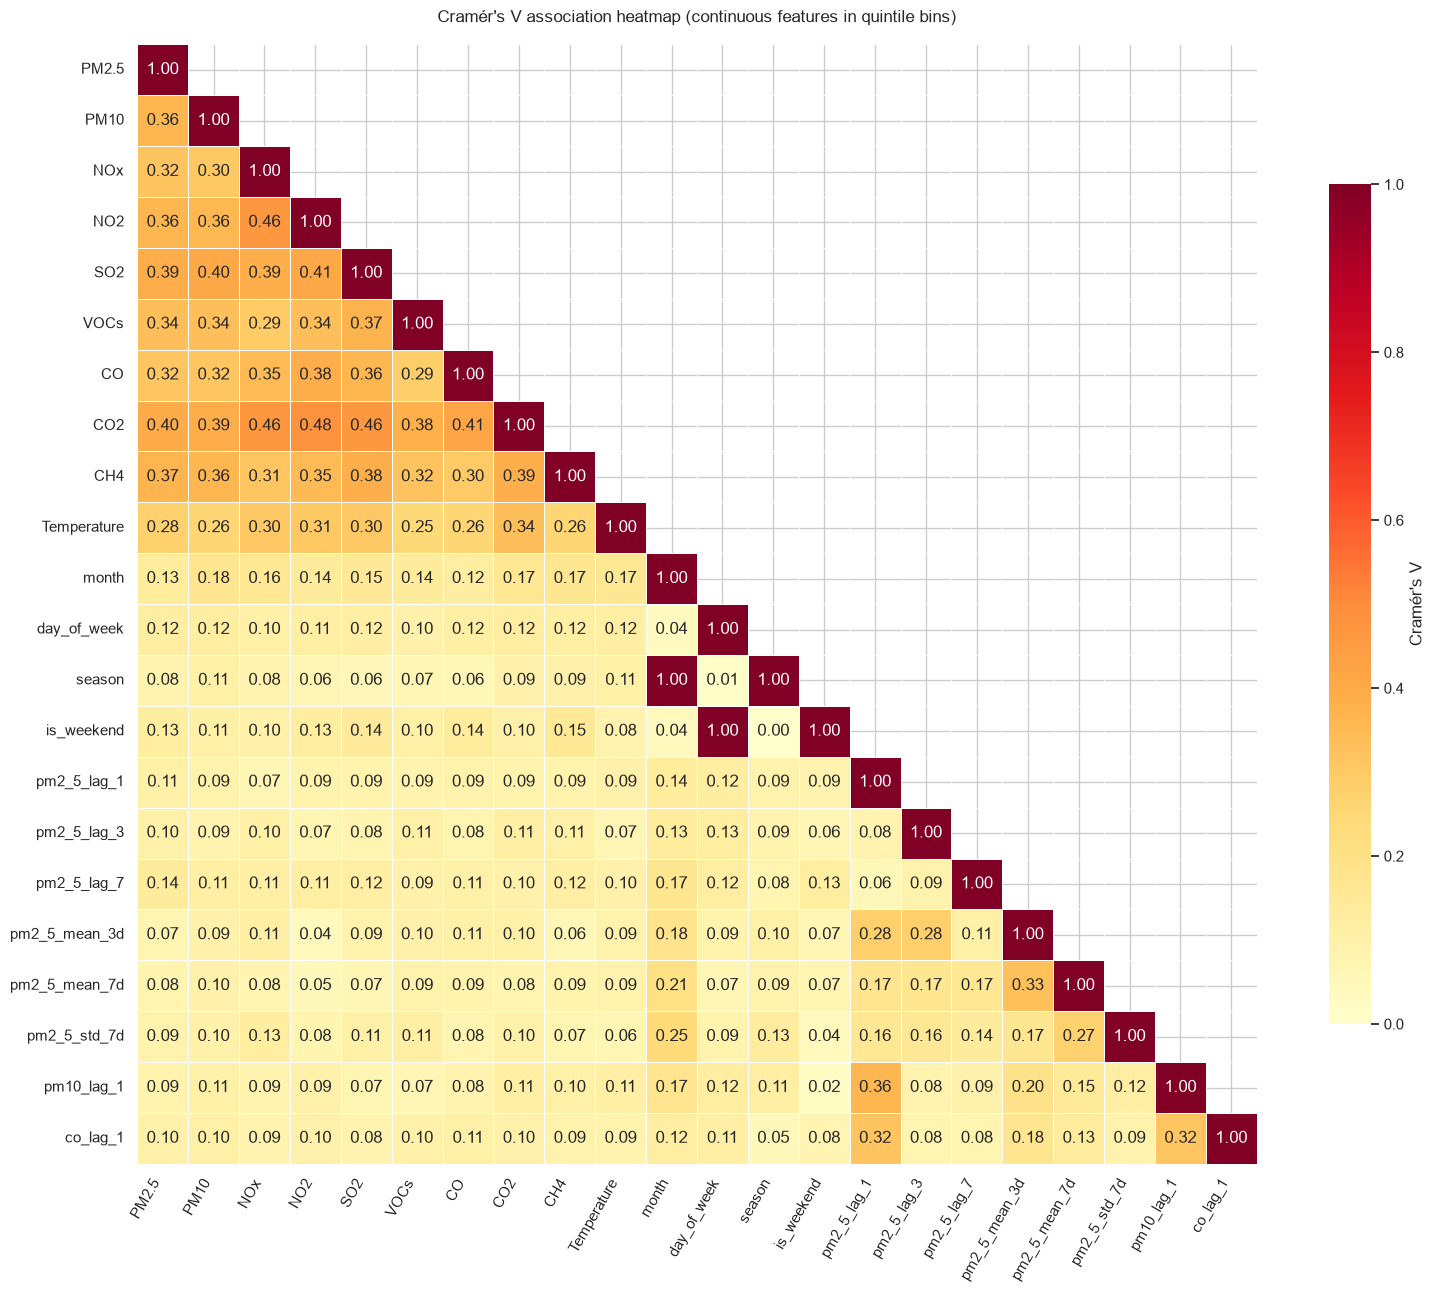

In [22]:
n = len(analysis_cols)
cramers = pd.DataFrame(np.eye(n), index=analysis_cols, columns=analysis_cols)

for i, a in enumerate(analysis_cols):
    for b in analysis_cols[i + 1:]:
        v = cramers_v(binned_df[a], binned_df[b])
        cramers.loc[a, b] = v
        cramers.loc[b, a] = v

Path("assets").mkdir(exist_ok=True)

mask = np.triu(np.ones_like(cramers, dtype=bool), k=1)
plt.figure(figsize=(16, 13))
sns.heatmap(
    cramers,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.75, "label": "Cramér's V"},
)
plt.title("Cramér's V association heatmap (continuous features in quintile bins)", pad=16)
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("assets/cramers_v_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
pairs = (
    cramers.where(np.triu(np.ones_like(cramers, dtype=bool), k=1))
    .stack()
    .sort_values(ascending=False)
    .rename("cramers_v")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)

THRESHOLD = 0.45
strong = pairs[pairs["cramers_v"] >= THRESHOLD].reset_index(drop=True)

print(f"Pairs with Cramér's V >= {THRESHOLD}: {len(strong)}")
print(strong.round(3).to_string(index=False))

print("\nTop 20 pairs overall:")
print(pairs.head(20).round(3).to_string(index=False))

Pairs with Cramér's V >= 0.45: 6
  feature_1  feature_2  cramers_v
      month     season      1.000
day_of_week is_weekend      1.000
        NO2        CO2      0.480
        SO2        CO2      0.464
        NOx        NO2      0.464
        NOx        CO2      0.463

Top 20 pairs overall:
  feature_1  feature_2  cramers_v
      month     season      1.000
day_of_week is_weekend      1.000
        NO2        CO2      0.480
        SO2        CO2      0.464
        NOx        NO2      0.464
        NOx        CO2      0.463
         CO        CO2      0.414
        NO2        SO2      0.409
       PM10        SO2      0.403
      PM2.5        CO2      0.397
       PM10        CO2      0.393
      PM2.5        SO2      0.393
        CO2        CH4      0.388
        NOx        SO2      0.388
        SO2        CH4      0.384
        NO2         CO      0.384
       VOCs        CO2      0.382
        SO2       VOCs      0.368
      PM2.5        CH4      0.367
       PM10        CH4    

Index(['timestamp', 'PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature', 'month', 'day_of_week', 'is_weekend', 'season', 'pm2_5_lag_1', 'pm2_5_lag_3', 'pm2_5_lag_7',
       'pm2_5_mean_3d', 'pm2_5_mean_7d', 'pm2_5_std_7d', 'pm10_lag_1', 'co_lag_1'],
      dtype='str')

### Interpretation & candidates for combining (awaiting approval)

> Values are lower than the Pearson correlations seen earlier because quintile binning
> discards within-bin variation. Use this view for **non-linear / categorical association**,
> and Pearson for linear strength.

**Deterministic redundancy (V = 1.00)**
- `month` ↔ `season` — `season` is derived from `month`. Keep **one**. Recommendation:
  keep `month` for finer seasonality, or keep `season` if interpretability matters most.
- `day_of_week` ↔ `is_weekend` — `is_weekend` is derived from `day_of_week`. Keep
  `day_of_week` and drop `is_weekend`, or collapse both into one cyclical weekday feature.

**Combustion-gas cluster (V ≈ 0.41–0.48)**
- `NO2`–`CO2`, `SO2`–`CO2`, `NOx`–`NO2`, `NOx`–`CO2`, `CO`–`CO2`.
- Candidate: one **combustion composite** (PCA or scaled average), or keep `CO2` as the
  representative and drop its redundant partners.

**Particulate / secondary cluster (V ≈ 0.36–0.40)**
- `PM2.5`–`CO2`, `PM2.5`–`SO2`, `PM2.5`–`CH4`, `PM2.5`–`PM10`, `PM10`–`SO2`.
- **PM2.5 is the target**, so it must not be combined. `PM10`, `SO2`, `CH4` are candidates
  to replace one another.

**Lag / rolling block**
- Low mutual association (V ≤ 0.36). Only `pm2_5_lag_1`–`pm10_lag_1` (0.36) and
  `pm2_5_lag_1`–`co_lag_1` (0.32) stand out — little redundancy to remove here.

**No features have been combined or dropped.** Tell me which clusters you approve and I
will create the combined/encoded features.